# 03a. Logistic Regression from Scratch

**Goals.** By the end you can:

- **implement** logistic regression yourself, with NumPy only: the sigmoid, the predicted
  probabilities, the log-loss, its gradient, gradient descent, and predictions;
- **test** an implementation properly: shapes, a numerical gradient check, a loss that goes down, and
  agreement with scikit-learn;
- choose a **learning rate** by looking at the loss curve;
- **on your own**, use your implementation on real data.

**How this notebook works:** Part A has you write six functions, one at a time, each with a small check.
Part B is a **test suite** that we give you: if your functions pass it, your implementation is correct.
Part C uses it to look at the learning rate.

**Estimated time:** about 90 minutes.

## 0. Setup

In [54]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Interactive sliders (optional): if ipywidgets is missing, we show a few fixed pictures instead.
try:
    from ipywidgets import interact, FloatSlider, FloatLogSlider
    HAVE_WIDGETS = True
except ImportError:
    HAVE_WIDGETS = False
    print("ipywidgets is not installed: the interactive cells will show fixed pictures instead.")

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import sklearn.metrics as skmetrics

In [2]:
# --- exercise checker: just run this cell -----------------------------------------------
import base64 as _b64, json as _json
_ANS = _json.loads(_b64.b64decode("eyJXMSI6IDAuNSwgIlcyIjogImMiLCAiVysiOiAwLjc1LCAiQTEiOiB7ImFyZ3MiOiBbW1stMTAwMC4wLCAtMi4wLCAwLjAsIDMuMCwgMTAwMC4wXV1dLCAib3V0IjogW1s3LjEyNDU3NjQwNjc0MTI4NWUtMjE4LCAwLjExOTIwMjkyMjAyMjExNzU1LCAwLjUsIDAuOTUyNTc0MTI2ODIyNDMzNCwgMS4wXV19LCAiQTIiOiB7ImFyZ3MiOiBbW1tbMS4wLCAyLjBdLCBbMi4wLCAwLjBdLCBbMC4wLCAxLjBdLCBbMy4wLCAxLjBdXSwgWzAuNSwgLTAuNV0sIDAuMjVdXSwgIm91dCI6IFtbMC40Mzc4MjM0OTkxMTQyMDE5MywgMC43NzcyOTk4NjExNzQ2OTExLCAwLjQzNzgyMzQ5OTExNDIwMTkzLCAwLjc3NzI5OTg2MTE3NDY5MTFdXX0sICJBMyI6IHsiYXJncyI6IFtbWzEsIDAsIDEsIDFdLCBbMC45LCAwLjIsIDAuMywgMS4wXV1dLCAib3V0IjogWzAuMzgzMTE5MjE3ODI0NzQzMDZdfSwgIkE0IjogeyJhcmdzIjogW1tbWzEuMCwgMi4wXSwgWzIuMCwgMC4wXSwgWzAuMCwgMS4wXSwgWzMuMCwgMS4wXV0sIFsxLCAwLCAwLCAxXSwgWzAuNSwgLTAuNV0sIDAuMjVdXSwgIm91dCI6IFtbMC4wODEwODA3MDEyNDY5MTQzMywgLTAuMjI3MzA3NDEwMzcwNjc1NzgsIDAuMTA3NTYxNjgwMTQ0NDQ2NV1dfSwgIkE1IjogWzAuMjg0ODk2NzQ4MjgwODM5MzMsIDAuNTkzNTI5MDA5MzQxMTQ1OCwgLTAuNTEzNjYwNzExNTQ4NDk5MSwgMC42OTMxNDcxODA1NTk5NDUzLCAwLjUyOTk1NzE2ODc0MTIxNl0sICJBNiI6IHsiYXJncyI6IFtbW1sxLjAsIDIuMF0sIFsyLjAsIDAuMF0sIFswLjAsIDEuMF0sIFszLjAsIDEuMF1dLCBbMC41LCAtMC41XSwgMC4yNSwgMC41XSwgW1tbMS4wLCAyLjBdLCBbMi4wLCAwLjBdLCBbMC4wLCAxLjBdLCBbMy4wLCAxLjBdXSwgWzAuNSwgLTAuNV0sIDAuMjUsIDAuMl1dLCAib3V0IjogW1swLjAsIDEuMCwgMC4wLCAxLjBdLCBbMS4wLCAxLjAsIDEuMCwgMS4wXV19LCAiRDEiOiAwLjB9"))

def _has_str(v):
    return isinstance(v, str) or (isinstance(v, (list, tuple)) and any(_has_str(x) for x in v))

def _norm(v):
    return [_norm(x) for x in v] if isinstance(v, (list, tuple, np.ndarray)) else str(v).strip().lower()

def _close(a, b, tol):
    if _has_str(b):
        return _norm(a) == _norm(b)
    try:
        return np.allclose(np.asarray(a, dtype=float), np.asarray(b, dtype=float), atol=tol, rtol=0)
    except Exception:
        return False

def check(key, value, tol=1e-3):
    # Compare your answer for exercise `key` with the expected one.
    if value is None or value is Ellipsis or (isinstance(value, (list, tuple)) and any(v is None for v in value)):
        print(f"⏳ {key}: not answered yet")
    elif _close(value, _ANS[key], tol):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. You got {value}; check your work and try again")

def check_against(key, value, reference, tol=1e-3):
    # Compare your answer with a reference value computed in the same cell.
    if value is None or (isinstance(value, (list, tuple)) and any(v is None for v in value)):
        print(f"⏳ {key}: not answered yet")
    elif _close(value, reference, tol):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. You got {value}; check your work and try again")

def check_fn(key, fn, tol=1e-3):
    # Call your function on some test inputs and compare with the expected outputs.
    spec = _ANS[key]
    try:
        outs = [fn(*[np.array(a, dtype=float) for a in args]) for args in spec["args"]]
    except Exception as e:
        print(f"❌ {key}: your function raised an error: {type(e).__name__}: {e}")
        return
    if any(o is None for o in outs):
        print(f"⏳ {key}: not answered yet (your function returns None)")
    elif all(_close(o, ex, tol) for o, ex in zip(outs, spec["out"])):
        print(f"✅ {key}: correct!")
    else:
        print(f"❌ {key}: not yet. Your function gives {outs}; check your work and try again")

## Warm-up: notebook 02, and a look ahead

**W1.** A feature has training mean 10 and training standard deviation 4. What is the standardized
value of $x = 12$? Store it in `w1_answer`.

**W2** (a look ahead). `X` is an $N \times n$ array whose rows are the examples $x_i$, and `err` is an
array of length $N$ holding the errors $h_i - y_i$. Which NumPy expression computes the gradient
$\frac{1}{N}\sum_{i=1}^N (h_i - y_i)\, x_i$ (a vector of length $n$)? Store the letter in
`w2_answer`.

- (a) `X @ err / N`
- (b) `np.mean(err) * X`
- (c) `X.T @ err / N`
- (d) `err @ X.T / N`

In [7]:

w1_answer = (12 - 10)/4
w2_answer = 'c'
check("W1", w1_answer)
check("W2", w2_answer)

✅ W1: correct!
✅ W2: correct!


**Your answer:** *(write here)*

# Part A: implement

We'll work with **arrays of examples** all the time:

- `X` has shape `(N, n)`: one row per example, one column per feature;
- `y` has shape `(N,)`: the labels, 0 or 1;
- `w` has shape `(n,)`, and `b` is a number.

The key to fast, short code is **vectorization**: computing for all $N$ examples at once, with no
Python loops over the examples. For example, `X @ w + b` computes all $N$ scores
$z_i = w^T x_i + b$ in one line. That's the rule for Part A: **no loops over the examples.**

### A1. The sigmoid, done safely

`1 / (1 + np.exp(-z))` has a hidden problem. For a very negative $z$, like $-1000$, `np.exp(1000)` is
too big for the computer: it **overflows** to infinity, and NumPy prints a warning (in other formulas an
overflow gives `nan`, "not a number").

A simple fix: before exponentiating, **clip** $z$ into a safe range, say $[-500, 500]$, with
`np.clip(z, -500, 500)`. Since $\sigma(-500)$ is already $0$ and $\sigma(500)$ is already $1$ to
computer precision, clipping changes nothing, except that there's no more overflow.

Write `sigmoid(z)` for arrays, with clipping.

In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

check_fn("A1", sigmoid)

✅ A1: correct!


### A2. Predicted probabilities

Write `predict_proba(X, w, b)`, which returns the array of the $N$ probabilities
$h(x_i) = \sigma(w^T x_i + b)$.

In [13]:
def predict_proba(X, w, b):
    return sigmoid(w @ X.T + b)

check_fn("A2", predict_proba)

✅ A2: correct!


### A3. The log-loss

Write `log_loss(y, p)`, which returns the average log-loss:
$$L = -\frac{1}{N}\sum_{i=1}^N \big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\big]$$

Another hidden problem: if some $p_i$ is exactly 0 or 1, `np.log(0)` is $-\infty$. To be safe, first
clip the probabilities into $[10^{-12}, 1 - 10^{-12}]$. The test case includes a probability of exactly
1.0, to make sure you did.

In [14]:
def log_loss(y, p):
    return -np.mean(y*np.log(np.clip(p, 10**-12, 1 - (10**-12))) + ((1 - y)*(np.log(1 - np.clip(p, 10**-12, 1 - (10**-12))))))

check_fn("A3", log_loss)

✅ A3: correct!


### A4. The gradient

Write `gradient(X, y, w, b)`, which returns the pair `(grad_w, grad_b)`:
$$\nabla_w L = \frac{1}{N}\sum_{i=1}^N (h_i - y_i)\, x_i, \qquad
\frac{\partial L}{\partial b} = \frac{1}{N}\sum_{i=1}^N (h_i - y_i)$$

`grad_w` must be an array of shape `(n,)`. Use W2 from the warm-up, and no loops!

In [35]:
def gradient(X, y, w, b):
    return ((predict_proba(X, w, b) - y)@X)/X.shape[0], np.mean(predict_proba(X, w, b) - y)

def _gradient_flat(X, y, w, b):                 # (for the checker only)
    gw, gb = gradient(X, y, w, b)
    return None if gw is None else np.append(gw, gb)

check_fn("A4", _gradient_flat)

✅ A4: correct!


### A5. Training with gradient descent

Write `fit(X, y, eta, n_iter)`:

1. start from $w = 0$ (an array of zeros of length $n$) and $b = 0$;
2. repeat `n_iter` times: record the current log-loss in a list, compute the gradient, and take a step:
   $w \leftarrow w - \eta\,\nabla_w L$ and $b \leftarrow b - \eta\,\frac{\partial L}{\partial b}$;
3. return `w, b, loss_history`.

(Record the loss **before** each step, so `loss_history[0]` is the loss at the start.)

Here the loop is fine: it's a loop over **steps**, not over examples.

In [36]:
def fit(X, y, eta=0.1, n_iter=1000):
    w = np.zeros(X.shape[1])
    b = 0

    loss_history = []

    for i in range(n_iter):
        loss_history.append(log_loss(y, predict_proba(X, w, b)))
        dw, db = gradient(X, y, w, b)
        w -= eta*dw
        b -= eta*db

    return w, b, loss_history

X_small = np.array([[1.0, 2.0], [2.0, 0.0], [0.0, 1.0], [3.0, 1.0]])
y_small = np.array([1, 0, 0, 1])
w_s, b_s, L_s = fit(X_small, y_small, eta=0.1, n_iter=50)
print("w =", w_s, "  b =", b_s)
check("A5", None if w_s is None else list(w_s) + [b_s, L_s[0], L_s[-1]])

w = [0.28489675 0.59352901]   b = -0.5136607115484991
✅ A5: correct!


### A6. Predictions

Write `predict(X, w, b, threshold=0.5)`, which returns 0/1 predictions.

In [42]:
def predict(X, w, b, threshold=0.5):
    return predict_proba(X, w, b) > threshold

check_fn("A6", predict)

✅ A6: correct!


# Part B: the test suite

A good programmer doesn't trust code just because it runs. Here is a set of tests. **Run it**. If any
test fails, go back to Part A and fix your functions; that's the whole point of a test suite.

*You have:* your six functions from Part A, and the tiny dataset `X_small`, `y_small` (A5).

In [43]:
def part_a_done():
    # True once all six functions of Part A are implemented
    try:
        return (fit(X_small, y_small, 0.1, 1)[0] is not None
                and predict(X_small, np.zeros(2), 0.0) is not None)
    except Exception:
        return False

def run_tests():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(30, 3)); y = rng.integers(0, 2, size=30)
    w = rng.normal(size=3); b = 0.3
    results = {}

    # 1. shapes
    try:
        p = predict_proba(X, w, b); gw, gb = gradient(X, y, w, b)
        results["shapes"] = (np.shape(p) == (30,) and np.shape(gw) == (3,) and np.ndim(gb) == 0)
    except Exception as e:
        results["shapes"] = False

    # 2. no overflow warnings, and probabilities strictly inside [0, 1]
    try:
        with np.errstate(over="raise"):
            s = sigmoid(np.array([-1e4, 0.0, 1e4]))
        results["safe sigmoid"] = np.allclose(s, [0, 0.5, 1])
    except Exception:
        results["safe sigmoid"] = False

    # 3. numerical gradient check (central differences, as in 01a)
    try:
        eps = 1e-6
        gw, gb = gradient(X, y, w, b)
        num_w = np.zeros(3)
        for j in range(3):
            e = np.zeros(3); e[j] = eps
            num_w[j] = (log_loss(y, predict_proba(X, w + e, b)) - log_loss(y, predict_proba(X, w - e, b))) / (2 * eps)
        num_b = (log_loss(y, predict_proba(X, w, b + eps)) - log_loss(y, predict_proba(X, w, b - eps))) / (2 * eps)
        results["gradient check"] = np.allclose(gw, num_w, atol=1e-6) and abs(gb - num_b) < 1e-6
    except Exception:
        results["gradient check"] = False

    # 4. the loss goes down at every step (small learning rate)
    try:
        _, _, L = fit(X, y, eta=0.05, n_iter=200)
        results["loss decreases"] = len(L) == 200 and np.all(np.diff(L) <= 1e-12)
    except Exception:
        results["loss decreases"] = False

    for name, ok in results.items():
        print(("✅ " if ok else "❌ ") + name)
    return all(results.values())

all_passed = run_tests()

✅ shapes
✅ safe sigmoid
✅ gradient check
✅ loss decreases


### B1. The big test: do we agree with scikit-learn?

Our `fit` and sklearn's `LogisticRegression` minimize the **same** log-loss, so, if both are run long
enough, they should find the **same** $w$ and $b$.

One detail: sklearn adds regularization by default (explained in 03b). To turn it off we pass a huge
`C`, like `C=1e10`, which means "practically no regularization".

We'll use the 5-feature dataset from 01b, where we know the true weights.

In [44]:
rng = np.random.default_rng(5)
w_true = np.array([2.0, -1.5, 1.0, 0.0, 0.5])
b_true = -0.5
X5 = rng.normal(size=(1000, 5))
y5 = (rng.uniform(size=1000) < 1 / (1 + np.exp(-(X5 @ w_true + b_true)))).astype(int)

if part_a_done():
    w_mine, b_mine, L_mine = fit(X5, y5, eta=0.5, n_iter=2000)
    sk = LogisticRegression(C=1e10).fit(X5, y5)

    print("mine:    w =", np.round(w_mine, 4), "  b =", round(b_mine, 4))
    print("sklearn: w =", np.round(sk.coef_[0], 4), "  b =", round(sk.intercept_[0], 4))
    max_diff = np.max(np.abs(predict_proba(X5, w_mine, b_mine) - sk.predict_proba(X5)[:, 1]))
    print("largest difference in predicted probability:", max_diff)
    print("✅ agrees with sklearn!" if max_diff < 1e-3 else "❌ doesn't agree yet: check your functions")
else:
    print("⏳ finish Part A first: this cell uses your functions.")

mine:    w = [ 2.0435 -1.3981  1.0409 -0.0167  0.4396]   b = -0.5677
sklearn: w = [ 2.0435 -1.3979  1.0404 -0.0169  0.4393]   b = -0.5676
largest difference in predicted probability: 0.00029467610345612627
✅ agrees with sklearn!


If you see ✅: **congratulations, you've implemented logistic regression.** The same model that
sklearn fits, from about 20 lines of NumPy.

### B2. See it work

Train your implementation on the 01b clinic data (scaled first, since gradient descent likes scaled
data; see 02). Then draw the decision boundary from **your** weights.

In [45]:
def make_patients(n, seed):
    rng = np.random.default_rng(seed)
    y = (rng.uniform(size=n) < 0.4).astype(int)
    healthy = rng.normal([3.5, 3.0], 1.3, size=(n, 2))
    sick = rng.normal([6.0, 5.0], 1.3, size=(n, 2))
    return np.round(np.where(y[:, None] == 1, sick, healthy), 2), y

X_pat, y_pat = make_patients(200, seed=0)
scaler = StandardScaler().fit(X_pat)
X_pat_s = scaler.transform(X_pat)

training accuracy: 0.925


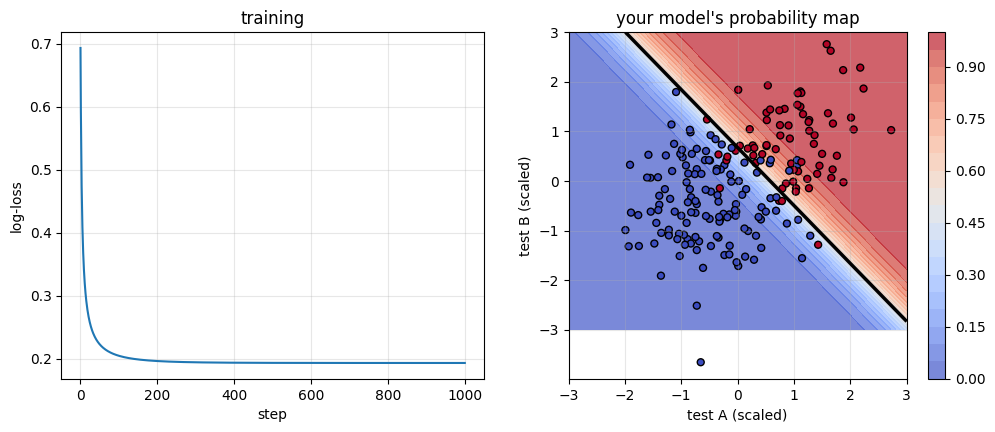

In [46]:
if part_a_done():
    w_p, b_p, L_p = fit(X_pat_s, y_pat, eta=0.5, n_iter=1000)
    print("training accuracy:", np.mean(predict(X_pat_s, w_p, b_p) == y_pat))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(L_p)
    axes[0].set_xlabel("step"); axes[0].set_ylabel("log-loss"); axes[0].set_title("training")
    g1, g2 = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    probs = predict_proba(np.column_stack([g1.ravel(), g2.ravel()]), w_p, b_p).reshape(g1.shape)
    cs = axes[1].contourf(g1, g2, probs, levels=np.linspace(0, 1, 21), cmap="coolwarm", alpha=0.7)
    axes[1].contour(g1, g2, probs, levels=[0.5], colors="k", linewidths=2.5)
    axes[1].scatter(X_pat_s[:, 0], X_pat_s[:, 1], c=y_pat, cmap="coolwarm", edgecolor="k", s=25)
    axes[1].set_xlabel("test A (scaled)"); axes[1].set_ylabel("test B (scaled)")
    axes[1].set_title("your model's probability map")
    fig.colorbar(cs, ax=axes[1])
    plt.show()
else:
    print("⏳ finish Part A first: this cell uses your functions.")

# Part C: the learning rate

You met the learning rate $\eta$ when you learned gradient descent. Let's see what it does here: train
on the scaled clinic data (`X_pat_s`, `y_pat` from B2) with several values of $\eta$, and compare the
loss curves.

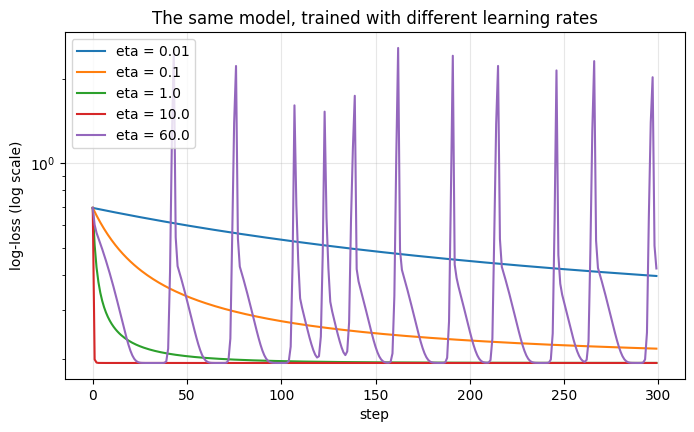

eta = 0.01   loss after 300 steps = 0.39573
eta = 0.1    loss after 300 steps = 0.21754
eta = 1.0    loss after 300 steps = 0.19340
eta = 10.0   loss after 300 steps = 0.19333
eta = 60.0   loss after 300 steps = 0.42101


In [47]:
if part_a_done():
    etas = [0.01, 0.1, 1.0, 10.0, 60.0]
    plt.figure(figsize=(8, 4.5))
    final_losses = {}
    for eta in etas:
        _, _, L = fit(X_pat_s, y_pat, eta=eta, n_iter=300)
        final_losses[eta] = L[-1]
        plt.plot(L, label=f"eta = {eta}")
    plt.yscale("log")
    plt.xlabel("step"); plt.ylabel("log-loss (log scale)")
    plt.legend(); plt.title("The same model, trained with different learning rates")
    plt.show()
    for eta, l in final_losses.items():
        print(f"eta = {eta:<5}  loss after 300 steps = {l:.5f}")
else:
    print("⏳ finish Part A first: this cell uses your functions.")

**Exercise C1.** Answer from the plot and the printed numbers:

1. Which learning rates are **too small**? How can you tell?
2. What happens with the **largest** learning rate?
3. If you could train for only 300 steps, which $\eta$ would you choose?

**Your answer:**
1. the values $0.01$ and $0.1$ are too small, as the loss never stabilizes (reach a final value)
1. it starts oscillating, probably for the same reason as a PID controller with a kp value too high
1. I would choose eta = 1.0, as it reaches the minimum loss quickly, but is still gradual, meaning it did not "skip" over possible correct values.

# On your own: your implementation on real data

Use **your own** functions (`fit`, `predict`) on the **banknotes** from notebook 02
(`../data/data_banknote_authentication.txt`, no header row; 4 feature columns, then the label).

1. Load the data, split it (30% test, `stratify`, `random_state=0`) and scale it, as in 02.
2. Train with your `fit` for 1000 steps, with a few learning rates. Plot the loss curves, and choose
   $\eta$ by looking at them.
3. Compute the **test accuracy** of your model with the chosen $\eta$, and store it in `my_acc`.
4. Compare with sklearn: fit `LogisticRegression()` on the same scaled data and store its test accuracy
   in `sk_acc`. The check passes when the two are within 0.01 of each other.

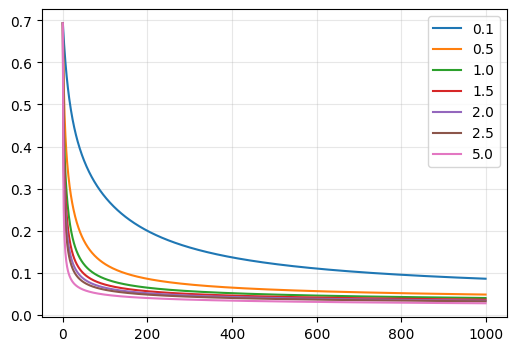

my test accuracy: 0.9951456310679612    sklearn: 0.9927184466019418
✅ On your own: correct!


In [55]:
cols = ["variance", "skewness", "curtosis", "entropy", "label"]
bank = pd.read_csv("./data/data_banknote_authentication.txt", header=None, names=cols)
X_bank = bank[["variance", "skewness", "curtosis", "entropy"]].values
y_bank = bank["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_bank, y_bank, test_size=0.3, stratify=y_bank, random_state=0)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

etas = [0.1, 0.5, 1.0, 1.5, 2.0, 2.5, 5.0]
for eta in etas:
    my_w, my_b, my_loss_history = fit(X_train_s, y_train, eta=eta, n_iter=1000)
    plt.plot(my_loss_history, label=f"{eta}")
plt.legend()
plt.show()

chosen_eta = 5.0

my_w, my_b, my_loss_history = fit(X_train_s, y_train, eta=chosen_eta, n_iter=1000)

my_acc = skmetrics.accuracy_score(y_test, predict(X_test_s, my_w, my_b))

regression = LogisticRegression()
regression.fit(X_train_s, y_train)

sk_acc = skmetrics.accuracy_score(y_test, regression.predict(X_test_s))
print("my test accuracy:", my_acc, "   sklearn:", sk_acc)
check_against("On your own", my_acc, sk_acc, tol=0.01)

**Think about it:** on the banknotes, the loss keeps going down, slowly, even after 1000 steps with
a large $\eta$, and the test accuracy is above 99%. Remember from 02 that the banknote classes
are **almost linearly separable**. What would happen to the weights if we kept training forever?
(Notebook 03b starts exactly here.)

**Your answer:** *(write here)*
the weights would slowly get more and more accurate, probably to the point where floating point precision would get in our way.

## Going further

The **full version** of this notebook (`03a_from_scratch_full_student.ipynb`) also has these parts, for anyone who wants more:

- W+. One more warm-up question: recall
- C+. A too-large learning rate on unscaled data
- Part D: does the choice of sigmoid matter? (an experiment, and a trap)

## Recap

- You implemented logistic regression with NumPy:
  - the sigmoid (with clipping against overflow);
  - `predict_proba = sigmoid(X @ w + b)`;
  - the log-loss (with clipping against `log(0)`);
  - the gradient `X.T @ (h - y) / N`;
  - gradient descent, and `predict`.
- **Testing:** check the shapes, check the gradient numerically, check that the loss goes down, and
  compare with a trusted implementation (sklearn with `C=1e10`, practically no regularization).
- **The learning rate:** too small is slow, too large overshoots and bounces. Look at the loss curve.
- **Next (03b):** what happens to logistic regression on data that is *too* easy (perfectly
  separable), and the fix: **regularization**, the mysterious extra term sklearn has been adding all
  along.

## References and further reading

- **[Logistic Regression](https://mlu-explain.github.io/logistic-regression/)**, MLU-Explain: a visual
  review of the model you just implemented.
- NumPy documentation:
  [broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html) (how operations on arrays
  of different shapes work) and
  [`np.clip`](https://numpy.org/doc/stable/reference/generated/numpy.clip.html).
- scikit-learn's
  [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html):
  the documentation of the parameter `C`, which we'll understand in 03b.